<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%2011/MRayhanZamzami_JS11_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 1 - Klasifikasi SVM dengan Data Dummy Linier

Konsep margin maksimal, hyperplane, dan support vectors.

## Langkah 1 - Import Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

## Langkah 2 - Membuat Data Dummy

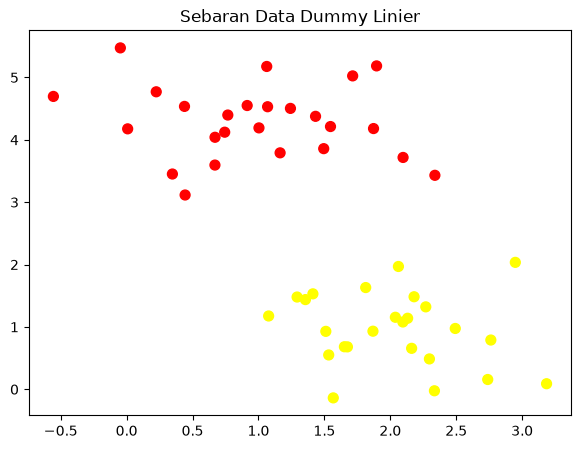

In [2]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title('Sebaran Data Dummy Linier')
plt.show()

## Langkah 3 - Ilustrasi Garis Pemisah Linier

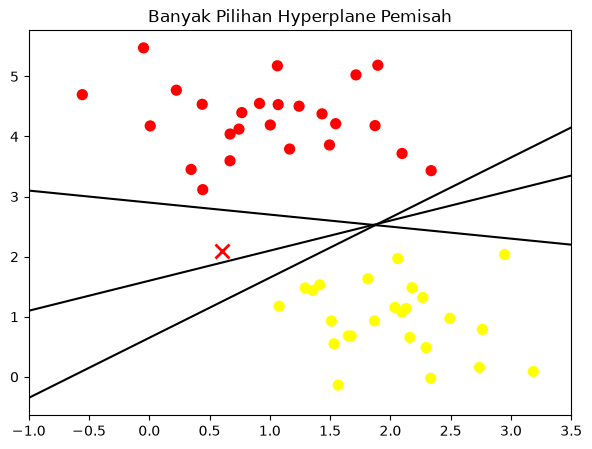

In [3]:
xfit = np.linspace(-1, 3.5)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.title('Banyak Pilihan Hyperplane Pemisah')
plt.show()

## Langkah 4 - Ilustrasi Margin Maksimal

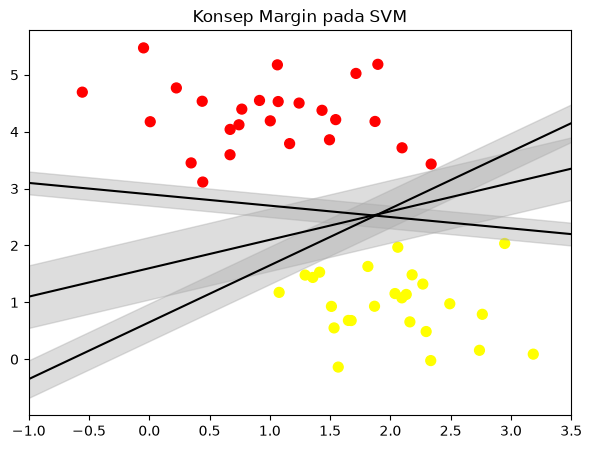

In [4]:
xfit = np.linspace(-1, 3.5)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none', color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title('Konsep Margin pada SVM')
plt.show()

## Langkah 5 - Fitting Model SVM Linier

In [5]:
from sklearn.svm import SVC

model = SVC(kernel='linear', C=1E10)
model.fit(X, y)
print('Model SVM berhasil difitting')

Model SVM berhasil difitting


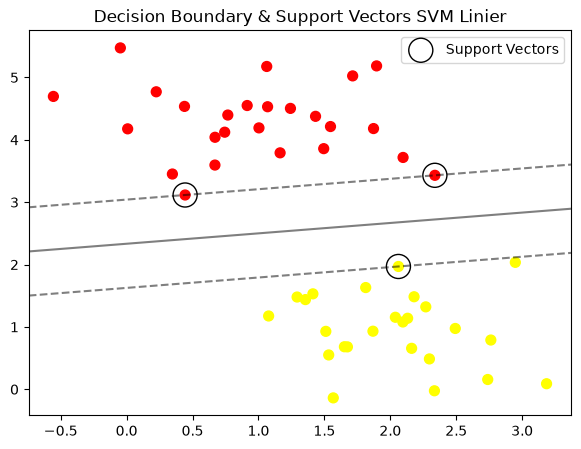

In [6]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # Plot decision boundary dan margin
    ax.contour(X_grid, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, edgecolors='black', facecolors='none', label='Support Vectors')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.title('Decision Boundary & Support Vectors SVM Linier')
plt.legend()
plt.show()

In [7]:
# Titik-titik Support Vectors
print('Koordinat Support Vectors:')
print(model.support_vectors_)

Koordinat Support Vectors:
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]


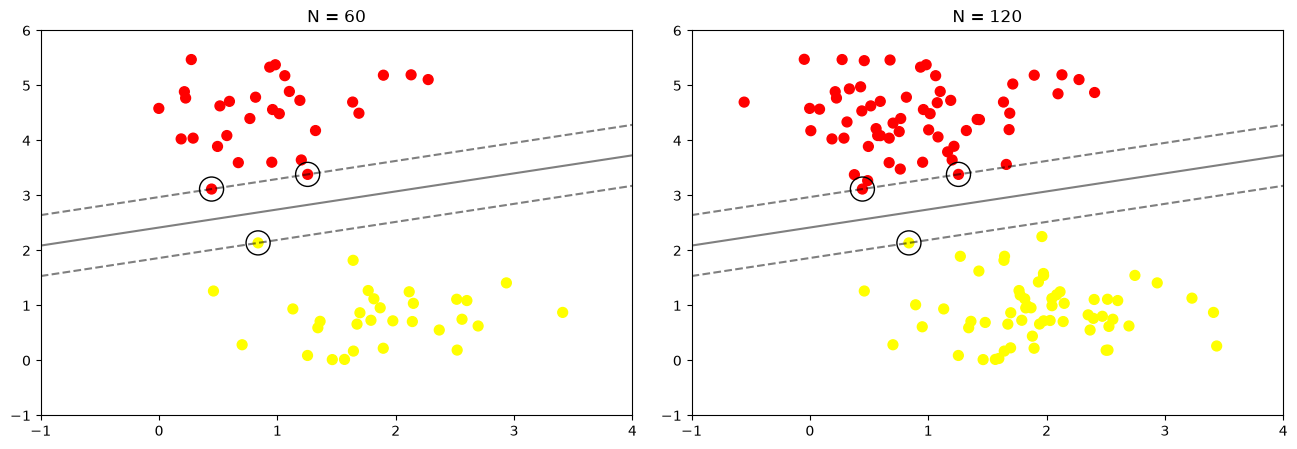

In [8]:
# Pengaruh jumlah data terhadap posisi hyperplane
def plot_svm(N=10, ax=None):
    X_sub, y_sub = make_blobs(n_samples=200, centers=2, random_state=0, cluster_std=0.60)
    X_sub = X_sub[:N]
    y_sub = y_sub[:N]
    clf = SVC(kernel='linear', C=1E10)
    clf.fit(X_sub, y_sub)

    ax = ax or plt.gca()
    ax.scatter(X_sub[:, 0], X_sub[:, 1], c=y_sub, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(clf, ax)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title(f'N = {N}')
plt.show()